# Case study: a DR Congo microgrid (Idjwi Island)

**Purpose.** Apply the methods of the MiniGrid Meter Monitor pipeline (data-quality measurement, 15-minute
energy slots and the same rule-based anomaly checks) to a different kind of data: high-resolution electrical
measurements from a microgrid in the Democratic Republic of the Congo.

**The site.** An industrial campus at Kalenge, on Idjwi Island in Lake Kivu, run by the development
organisation PROLASA. It is supplied by a small micro-hydro plant (about 20 kW) with a diesel generator as
backup. It is **not** a solar mini-grid and is **not** operated by a commercial mini-grid company.

**The data.** Luh, M., Phipps, K., Britto, A., Wolf, M., Lutz, M. and Kraft, J. (2022). *High-Resolution
Real-World Electricity Data from Three Microgrids in the Global South*. Karlsruhe Institute of Technology,
https://doi.org/10.35097/1305 (CC BY 4.0). Files used, saved unchanged in `data/source/kit/`:

| File | Content |
|---|---|
| `drcongo_idjwi_main_distribution_v07.csv` | Whole site: voltage, current, power, frequency, harmonics |
| `drcongo_idjwi_corn_mill_v07.csv` | Corn mill: voltage, current, power |
| `drcongo_idjwi_metal_workshop_v07.csv` | Metal workshop: voltage, current, power |
| `Symbols_Units_Explanations_v03.xlsx` | Column definitions, units and site notes |

**Site notes from the data publishers** (units file):
- The electronic load controller is broken, so the **grid frequency is not regulated**: it rises when demand
  is low and falls when demand is high.
- The diesel generator is started by hand when a high load is planned. Its operation shows as a **stable
  50 Hz** frequency.
- The logger can only measure frequency between 40 and 70 Hz; values outside are capped.

Unlike the Renewvia data, there are **no customer accounts, tariffs or payments**, so this case study covers
operations and power quality, not revenue.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, "..")          # import the pipeline's own modules from the project root
import anomalies                  # the same five rules used on the Renewvia meters
import config

KIT = Path("../data/source/kit")
STEP_S = 5                        # the logger writes one row every 5 seconds
SLOT_MIN = config.INTERVAL_MINUTES  # 15-minute slots, as in the main pipeline
READS_PER_SLOT = SLOT_MIN * 60 // STEP_S   # 180 readings in a full slot
pd.set_option("display.width", 120)

## 1. Loading and data quality

Timestamps are read in local time (Central Africa Time, UTC+2) for the daily analysis. Duplicate timestamps
are removed. **Availability** is the share of expected 5-second readings that exist, the same idea as
completeness in the main pipeline.

In [2]:
cols = ["timestamp_local", "V_1N", "V_2N", "V_3N", "P_tot", "f", "THD_V_1N"]
main = pd.read_csv(KIT / "drcongo_idjwi_main_distribution_v07.csv", sep=";", usecols=cols)
main["t"] = pd.to_datetime(main["timestamp_local"], format="%d.%m.%Y %H:%M:%S")
duplicates = main["t"].duplicated().sum()
main = main.drop_duplicates("t").set_index("t").drop(columns="timestamp_local").sort_index()

start, end = main.index.min(), main.index.max()
expected = (end - start).total_seconds() / STEP_S + 1
print(f"Period: {start} to {end} local time ({(end - start) / pd.Timedelta('1D'):.1f} days)")
print(f"Readings: {len(main):,} ({duplicates} duplicate timestamps removed)")
print(f"Availability: {len(main) / expected:.1%} of the expected 5-second readings")

Period: 2022-01-16 17:55:10 to 2022-02-21 08:35:00 local time (35.6 days)
Readings: 399,620 (24 duplicate timestamps removed)
Availability: 64.9% of the expected 5-second readings


**GAP rule.** As in the main pipeline, a silence of 6 hours or more is a GAP, with the same severity
levels (low up to 24 h, medium up to 72 h, high beyond).

In [3]:
gap = main.index.to_series().diff()
long = gap[gap >= pd.Timedelta(hours=config.GAP_MIN_HOURS)]
gaps = pd.DataFrame({
    "from": long.index - long.values,
    "to": long.index,
    "hours": (long.dt.total_seconds() / 3600).round(1).values,
})
gaps["severity"] = [config.severity_for(h, config.GAP_SEVERITY_HOURS) for h in gaps["hours"]]
print(f"{len(gaps)} gaps of {config.GAP_MIN_HOURS} h or more, {gaps['hours'].sum():.0f} h in total")
gaps

5 gaps of 6 h or more, 271 h in total


,from,to,hours,severity
0,2022-01-19 07:15:00,2022-01-19 14:01:05,6.8,low
1,2022-01-19 16:05:00,2022-01-23 15:20:20,95.3,high
2,2022-01-23 16:35:00,2022-01-27 08:01:50,87.4,high
3,2022-01-27 10:20:00,2022-01-30 13:14:30,74.9,high
4,2022-01-31 23:30:00,2022-02-01 06:19:35,6.8,low


## 2. Site load

Power readings are averaged per 15-minute slot and converted to energy (kWh = mean W / 1000 × 0.25 h), the
same method the main pipeline uses for solar-system monitoring. A slot counts as measured when at least half
of its 180 readings exist. Daily energy is reported only for days with at least 90% of slots measured
(`GENERATION_MIN_COVERAGE`, as in the main pipeline).

In [4]:
slot = main["P_tot"].resample(f"{SLOT_MIN}min").agg(["mean", "count"])
slot = slot[slot["count"] >= READS_PER_SLOT / 2]
slot["kwh"] = slot["mean"] / 1000 * SLOT_MIN / 60

daily = slot.groupby(slot.index.normalize()).agg(kwh=("kwh", "sum"), slots=("kwh", "size"))
full = daily[daily["slots"] >= config.GENERATION_MIN_COVERAGE * config.SLOTS_PER_DAY]
print(f"Days with >= 90% of slots measured: {len(full)} of {len(daily)} days with any data")
print(f"Energy on those days: median {full['kwh'].median():.0f} kWh/day, "
      f"range {full['kwh'].min():.0f}-{full['kwh'].max():.0f} kWh/day")
print(f"Average load: {main['P_tot'].mean() / 1000:.1f} kW; "
      f"99th percentile: {main['P_tot'].quantile(0.99) / 1000:.1f} kW; maximum: {main['P_tot'].max() / 1000:.1f} kW")

Days with >= 90% of slots measured: 19 of 29 days with any data
Energy on those days: median 87 kWh/day, range 27-139 kWh/day
Average load: 3.6 kW; 99th percentile: 17.8 kW; maximum: 29.1 kW


Peak hour: 10:00 (5.3 kW); lowest hour: 2:00 (2.7 kW)


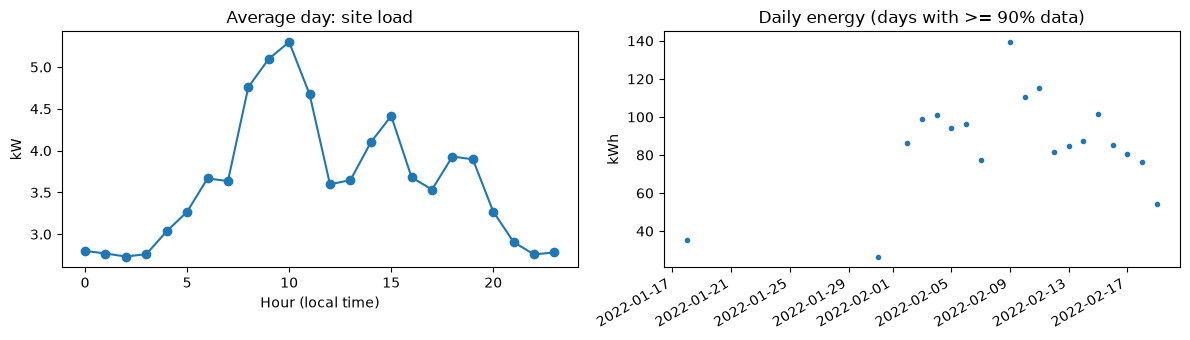

In [5]:
profile = main.groupby(main.index.hour)["P_tot"].mean() / 1000
peak = profile.idxmax()
print(f"Peak hour: {peak}:00 ({profile.max():.1f} kW); lowest hour: {profile.idxmin()}:00 ({profile.min():.1f} kW)")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
profile.plot(ax=ax[0], marker="o")
ax[0].set(title="Average day: site load", xlabel="Hour (local time)", ylabel="kW")
full["kwh"].plot(ax=ax[1], marker=".", linestyle="")
ax[1].set(title="Daily energy (days with >= 90% data)", xlabel="", ylabel="kWh")
plt.tight_layout()

## 3. Frequency: an unregulated grid

The reference used is EN 50160, the European standard for supply voltage characteristics. For **islanded
systems** (not connected to a large grid) it allows **50 Hz ± 2% (49–51 Hz) for 95% of a week** and
**50 Hz ± 15% (42.5–57.5 Hz) at all times**. These limits are used as a benchmark only: a small
micro-hydro system is not bound by a European standard, but the limits show how far the frequency
departs from what electrical equipment is designed for.

In [6]:
f = main["f"].dropna()
within_2 = f.between(49, 51).mean()
within_15 = f.between(42.5, 57.5).mean()
capped_high = (f >= 70).mean()
print(f"Within 49-51 Hz:     {within_2:.1%}  (EN 50160 islanded: >= 95%)")
print(f"Within 42.5-57.5 Hz: {within_15:.1%}  (EN 50160 islanded: 100%)")
print(f"At the 70 Hz cap:    {capped_high:.1%}  (real value may be higher)")
print(f"Median frequency:    {f.median():.1f} Hz")

bands = pd.cut(main["f"], [40, 45, 49, 51, 55, 60, 65, 70], include_lowest=True)
table = main.groupby(bands, observed=True)["P_tot"].agg(["size", "median"])
table["share_of_time_pct"] = (100 * table["size"] / table["size"].sum()).round(1)
table["median_load_kw"] = (table["median"] / 1000).round(1)
table[["share_of_time_pct", "median_load_kw"]]

Within 49-51 Hz:     13.4%  (EN 50160 islanded: >= 95%)
Within 42.5-57.5 Hz: 28.7%  (EN 50160 islanded: 100%)
At the 70 Hz cap:    28.3%  (real value may be higher)
Median frequency:    63.5 Hz


,share_of_time_pct,median_load_kw
f,,
"(39.999, 45.0]",0.2,0.8
"(45.0, 49.0]",0.4,3.0
"(49.0, 51.0]",13.4,2.1
"(51.0, 55.0]",8.4,3.0
"(55.0, 60.0]",14.3,4.4
"(60.0, 65.0]",16.8,3.7
"(65.0, 70.0]",46.6,3.3


**Does frequency follow load?** The publishers describe an unregulated turbine that speeds up when demand is
low. The test below compares load at the 70 Hz measurement cap with load elsewhere, and measures the rank
correlation between frequency and load where the frequency is actually measured (between the 40 and 70 Hz
caps), excluding the regulated 49.5–50.5 Hz band studied in section 4.

In [7]:
capped = main["f"] >= 70
print(f"Median load at the 70 Hz cap: {main.loc[capped, 'P_tot'].median() / 1000:.1f} kW "
      f"vs {main.loc[~capped & main['f'].notna(), 'P_tot'].median() / 1000:.1f} kW below it")

free = main[main["f"].between(40, 70, inclusive="neither") & ~main["f"].between(49.5, 50.5)]
rank_corr = free["f"].rank().corr(free["P_tot"].rank())   # Spearman correlation, written out
print(f"Rank correlation of frequency and load between the caps: {rank_corr:.2f} ({len(free):,} readings)")

Median load at the 70 Hz cap: 2.6 kW vs 3.5 kW below it
Rank correlation of frequency and load between the caps: 0.04 (235,276 readings)


## 4. Regulated 50 Hz periods (possibly diesel)

The publishers note that diesel operation shows as a stable 50 Hz. **Rule:** a regulated period is a run of
at least **10 minutes** with frequency between **49.5 and 50.5 Hz** and no break in the readings longer than
10 seconds. The 10-minute minimum separates sustained regulation from the moments when the unregulated
frequency simply passes through 50 Hz on its way up or down. The data alone cannot prove that the diesel
generator was running, so these periods are called *regulated*, not *diesel*.

In [8]:
DIESEL_BAND = (49.5, 50.5)
DIESEL_MIN_MINUTES = 10

in_band = main["f"].between(*DIESEL_BAND)
break_in_data = main.index.to_series().diff() > pd.Timedelta(seconds=2 * STEP_S)
run_id = ((in_band != in_band.shift()) | break_in_data).cumsum()

runs = (main[in_band].assign(run=run_id[in_band]).reset_index()
        .groupby("run").agg(start=("t", "min"), end=("t", "max"), median_kw=("P_tot", "median")))
runs["minutes"] = (runs["end"] - runs["start"]).dt.total_seconds() / 60
diesel = runs[runs["minutes"] >= DIESEL_MIN_MINUTES].copy()
diesel["median_kw"] = (diesel["median_kw"] / 1000).round(1)

hydro = main[~in_band]["P_tot"]
print(f"Regulated periods: {len(diesel)}, {diesel['minutes'].sum() / 60:.1f} h in total")
print(f"Median load during regulated periods: {diesel['median_kw'].median():.1f} kW "
      f"vs {hydro.median() / 1000:.1f} kW outside the 49.5-50.5 Hz band")
print(f"Runs in the 49.5-50.5 Hz band shorter than {DIESEL_MIN_MINUTES} min (not counted): "
      f"{(runs['minutes'] < DIESEL_MIN_MINUTES).sum():,}")
diesel["minutes"] = diesel["minutes"].round(1)
diesel.sort_values("minutes", ascending=False).head(10)

Regulated periods: 29, 61.1 h in total
Median load during regulated periods: 2.2 kW vs 3.4 kW outside the 49.5-50.5 Hz band
Runs in the 49.5-50.5 Hz band shorter than 10 min (not counted): 997


,start,end,median_kw,minutes
run,,,,
1,2022-01-16 17:55:10,2022-01-17 08:56:05,2.1,900.9
11,2022-01-17 20:52:10,2022-01-18 09:10:00,0.4,737.8
17,2022-01-18 21:59:40,2022-01-19 03:15:00,0.3,315.3
14,2022-01-18 14:55:05,2022-01-18 19:40:00,2.3,284.9
12,2022-01-18 09:19:35,2022-01-18 13:40:00,1.7,260.4
18,2022-01-19 03:21:10,2022-01-19 06:01:30,2.1,160.3
10,2022-01-17 18:00:15,2022-01-17 20:40:00,2.2,159.8
9,2022-01-17 15:55:25,2022-01-17 17:55:00,0.4,119.6
1509,2022-02-08 03:36:40,2022-02-08 05:19:30,2.7,102.8


In [9]:
share = in_band.groupby(main.index.to_period("M")).mean().mul(100).round(1)
print("Share of readings in the 49.5-50.5 Hz band, by month (%):")
print(share.to_string())
print("\nRegulated periods by month:")
print(diesel["start"].dt.to_period("M").value_counts().sort_index().to_string())

Share of readings in the 49.5-50.5 Hz band, by month (%):
t
2022-01    64.6
2022-02     2.1
Freq: M

Regulated periods by month:
start
2022-01    21
2022-02     8
Freq: M


## 5. Voltage and harmonics

EN 50160 asks that 95% of **10-minute mean** voltages lie within **±10% of nominal**. The nominal used is
230 V phase-to-neutral (IEC 60038); the result with the older 220 V nominal still used in parts of the DRC
is shown as a sensitivity check. Voltage harmonic distortion (THD) is compared with the EN 50160 limit of
**8%**, also on 10-minute means.

In [10]:
ten = main[["V_1N", "V_2N", "V_3N", "THD_V_1N"]].resample("10min").mean().dropna()
rows = []
for nominal in (230, 220):
    low, high = 0.9 * nominal, 1.1 * nominal
    for phase in ["V_1N", "V_2N", "V_3N"]:
        v = ten[phase]
        rows.append({"nominal_V": nominal, "phase": phase,
                     "within_10pct": f"{v.between(low, high).mean():.1%}",
                     "below": f"{(v < low).mean():.1%}", "above": f"{(v > high).mean():.1%}"})
print(f"{len(ten):,} ten-minute periods")
print(f"THD (phase 1): 95th percentile {ten['THD_V_1N'].quantile(0.95):.1f}%, "
      f"10-minute periods above 8%: {(ten['THD_V_1N'] > 8).mean():.2%}")
pd.DataFrame(rows)

3,428 ten-minute periods
THD (phase 1): 95th percentile 3.1%, 10-minute periods above 8%: 0.00%


,nominal_V,phase,within_10pct,below,above
0,230,V_1N,57.0%,36.9%,6.1%
1,230,V_2N,61.1%,34.8%,4.1%
2,230,V_3N,66.3%,31.6%,2.0%
3,220,V_1N,59.8%,28.1%,12.1%
4,220,V_2N,62.8%,25.4%,11.8%
5,220,V_3N,66.5%,24.2%,9.4%


## 6. Productive-use machines: the pipeline's anomaly rules on new meters

Each machine's three-phase power is converted into the format the anomaly rules expect: one row per
15-minute slot, energy in kWh, and an empty value when the slot has fewer than half of its readings. The
rules from `anomalies.py` then run **unchanged**, with the same thresholds and severities as for the
Renewvia customers.

In [11]:
def machine_slots(name: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Raw 5-second readings and 15-minute energy slots for one machine meter."""
    raw = pd.read_csv(KIT / f"drcongo_idjwi_{name}_v07.csv", sep=";",
                      usecols=["timestamp_utc", "V_1N", "P_1", "P_2", "P_3"])
    raw["t"] = pd.to_datetime(raw["timestamp_utc"], format="%d.%m.%Y %H:%M:%S", utc=True)
    raw = raw.drop_duplicates("t").set_index("t")
    raw["P"] = raw[["P_1", "P_2", "P_3"]].sum(axis=1, min_count=1)

    agg = raw["P"].resample(f"{SLOT_MIN}min").agg(["mean", "count"])
    kwh = (agg["mean"] / 1000 * SLOT_MIN / 60).where(agg["count"] >= READS_PER_SLOT / 2)
    slots = pd.DataFrame({"slot_start": agg.index, "energy_kwh_observed": kwh.to_numpy()})
    return raw, slots


summary, found = [], []
for name in ["corn_mill", "metal_workshop"]:
    raw, slots = machine_slots(name)
    summary.append({
        "machine": name,
        "readings": len(raw),
        "voltage_present_pct": round(100 * raw["V_1N"].gt(0).mean(), 1),
        "running_pct (> 100 W)": round(100 * raw["P"].gt(100).mean(), 2),
        "energy_kwh": round(raw["P"].clip(lower=0).sum() * STEP_S / 3600 / 1000, 1),
        "negative_readings": int(raw["P"].lt(0).sum()),
        "lowest_W": round(raw["P"].min()),
    })
    found.append(anomalies.run_all_rules(slots).assign(machine=name))

pd.DataFrame(summary)

,machine,readings,voltage_present_pct,running_pct (> 100 W),energy_kwh,negative_readings,lowest_W
0,corn_mill,391377,99.8,0.00,0.0,0,0
1,metal_workshop,399586,100.0,0.07,3.0,6245,-5797


In [12]:
events = pd.concat(found, ignore_index=True)
print("Anomaly events found by the pipeline's rules:")
print(events.groupby(["machine", "rule", "severity"]).size().rename("events").to_string())
events[events["rule"] != "GAP"].head(10)

Anomaly events found by the pipeline's rules:
machine         rule      severity
corn_mill       GAP       high         3
                          low          2
metal_workshop  GAP       high         3
                          low          2
                NEGATIVE  high        54
                SPIKE     low         10
                          medium       1


,rule,start,end,severity,details,machine
10,SPIKE,2022-01-17 13:00:00+00:00,2022-01-17 13:15:00+00:00,low,peak 0.0129 kWh vs typical 0.0020 kWh (6.4x),metal_workshop
11,SPIKE,2022-01-17 13:45:00+00:00,2022-01-17 16:00:00+00:00,low,peak 0.0192 kWh vs typical 0.0020 kWh (9.5x),metal_workshop
12,SPIKE,2022-02-05 05:15:00+00:00,2022-02-05 05:30:00+00:00,low,peak 0.0138 kWh vs typical 0.0018 kWh (7.7x),metal_workshop
13,SPIKE,2022-02-05 06:30:00+00:00,2022-02-05 08:30:00+00:00,medium,peak 0.0290 kWh vs typical 0.0018 kWh (16.1x),metal_workshop
14,SPIKE,2022-02-05 09:15:00+00:00,2022-02-05 12:00:00+00:00,low,peak 0.0164 kWh vs typical 0.0018 kWh (9.1x),metal_workshop
15,SPIKE,2022-02-10 16:45:00+00:00,2022-02-10 22:15:00+00:00,low,peak 0.0080 kWh vs typical 0.0014 kWh (5.7x),metal_workshop
16,SPIKE,2022-02-10 22:30:00+00:00,2022-02-10 23:00:00+00:00,low,peak 0.0072 kWh vs typical 0.0014 kWh (5.0x),metal_workshop
17,SPIKE,2022-02-11 00:00:00+00:00,2022-02-11 00:15:00+00:00,low,peak 0.0073 kWh vs typical 0.0015 kWh (5.0x),metal_workshop
18,SPIKE,2022-02-11 11:45:00+00:00,2022-02-11 12:00:00+00:00,low,peak 0.0080 kWh vs typical 0.0015 kWh (5.1x),metal_workshop
19,SPIKE,2022-02-15 03:15:00+00:00,2022-02-15 04:30:00+00:00,low,peak 0.0068 kWh vs typical 0.0010 kWh (6.8x),metal_workshop


**Why no ZERO_RUN for the corn mill?** The rule needs 3 days of *reported* zeros in a row, and a missing
slot breaks the run (a missing reading is not a proven zero). The check below shows what happened.

In [13]:
_, corn = machine_slots("corn_mill")
measured = corn["energy_kwh_observed"].notna()
zero = corn["energy_kwh_observed"].eq(0)
stretches = [last - first + 1 for first, last in anomalies.find_runs(zero)]
print(f"Measured slots at exactly 0 kWh: {zero.sum():,} of {measured.sum():,} ({zero.sum() / measured.sum():.0%})")
print(f"Empty slots (logger outages) breaking the zero stretches: {(~measured).sum():,}")
print(f"Zero stretches: {len(stretches)}, longest {max(stretches) / config.SLOTS_PER_DAY:.2f} days "
      f"(rule threshold: {config.ZERO_RUN_MIN_DAYS} days)")

Measured slots at exactly 0 kWh: 2,198 of 2,198 (100%)
Empty slots (logger outages) breaking the zero stretches: 1,177
Zero stretches: 43, longest 2.24 days (rule threshold: 3 days)


## 7. Findings

1. **Data availability is the first constraint.** The logger delivered 64.9% of expected readings over
   35.6 days, and three outages of 75–95 hours in late January account for most of the loss. Only 19 days
   are complete enough (≥ 90% of 15-minute slots) for daily energy totals.
2. **A daytime, productive-use load profile.** Average load is 3.6 kW, with a peak at 10:00 (5.3 kW) and a
   minimum at 02:00 (2.7 kW). Complete days used a median 87 kWh (27–139 kWh). Like Lorengelup in the main
   project, a campus with workshops peaks in the morning rather than the evening.
3. **Frequency is far outside normal limits.** Only 13.4% of readings are within 49–51 Hz (EN 50160 for
   islanded systems expects 95%) and only 28.7% within 42.5–57.5 Hz (expected: always). The median is
   63.5 Hz, and 28.3% of readings sit at the 70 Hz measurement cap, where load is lower (median 2.6 kW).
   That is consistent with the turbine over-speeding at low demand, as the publishers describe. Below the
   cap, frequency and load show no simple relationship (rank correlation 0.04).
4. **Two operating regimes.** In January, 64.6% of readings are at a regulated 50 Hz; in February, 2.1%.
   Of the 29 regulated periods of 10 minutes or more (61.1 h in total), 21 start in January and 8 in
   February, and load during them is *lower* than outside them (2.2 kW vs 3.4 kW). This does not match diesel use for planned high loads, so the cause
   (diesel, a working controller, or something else) cannot be confirmed from the data.
5. **Voltage is often too low.** Only 57–66% of 10-minute periods per phase are within ±10% of 230 V
   (EN 50160 expects 95%), and most deviations are under-voltage (32–37% of periods below 207 V). With a
   220 V nominal the result is similar (60–67%). Harmonic distortion is not a problem: the 95th percentile of
   voltage THD is 3.1%, and no 10-minute period exceeds the 8% limit.
6. **Productive-use equipment is installed, but barely used.** The corn mill was energised 99.8% of the time
   but consumed nothing in any measured slot. The metal workshop used 3.0 kWh in 36 days and ran above
   100 W only 0.07% of the time.
7. **The pipeline's rules transfer, and show their limits.** On the metal workshop, the NEGATIVE rule found
   54 events (6,245 negative 5-second readings, down to −5,797 W). A consumption meter cannot measure
   negative power, so this is a metering fault, such as a reversed current sensor. The ZERO_RUN rule did
   **not** flag the idle corn mill: frequent short logger outages split its zeros into stretches of at most
   2.24 days. For loggers with frequent outages, a complementary check, the share of measured slots at
   zero, catches what the run-based rule misses.

**What this means for an operator.** Installing productive-use machines does not guarantee productive-use
demand: utilisation needs to be measured per machine, as this data allows. Frequency and voltage quality
(here, a broken load controller) directly limit what equipment customers can safely run.

## 8. Limitations

- One site, 35.6 days, and two of the five machine meters; results do not generalise to other sites.
- Frequency is capped at 40 and 70 Hz by the logger, so extreme values are understated.
- The nominal voltage of the site is not documented; results are given for 230 V and 220 V.
- EN 50160 is used as a benchmark, not as a requirement that applies to this site.
- The site is a micro-hydro campus run by PROLASA, not a commercial solar mini-grid.